# New section

In [ ]:

import pandas as pd

file_path = "/content/Zimbabwe_Lithium_Research_Database_Populated.xlsx"

# Load the two sheets needed for our first comparison
observations = pd.read_excel(
    file_path,
    sheet_name="Project_Annual_Observations"
)

projects = pd.read_excel(
    file_path,
    sheet_name="Project_Registry"
)

print("Database loaded successfully!")
print("Total observations:", len(observations))


core_projects = projects[
    projects["Core_Case_Study"] == "Yes"
]

core_ids = core_projects["Project_ID"].tolist()

core_data = observations[
    observations["Project_ID"].isin(core_ids)
]

print(core_data[
    ["Project_ID", "Year", "Indicator", "Value", "Unit"]
])


comparison = pd.crosstab(
    core_data["Project_ID"],
    core_data["Indicator"]
)

print(comparison)

comparison.to_excel(
    "Zimbabwe_Lithium_Comparative_Matrix.xlsx"
)

print("Comparative matrix exported successfully!")



,Project,Year,Indicator,Value,Unit
4,Arcadia-Huayou Cobalt,2025,Employment_Direct_Local,2000.0,employees
10,Bikita Minerals,2022,Employment_Direct,320.000,employees
16,Bikita Minerals,2026,Employment_Direct,1407.0,employees
21,Sabi Star Lithium-Tantalum Mine,2024,Employment_Direct,450.000,employees
24,Sandawana Lithium Mine,2023,Employment_Direct,1000.000,employees


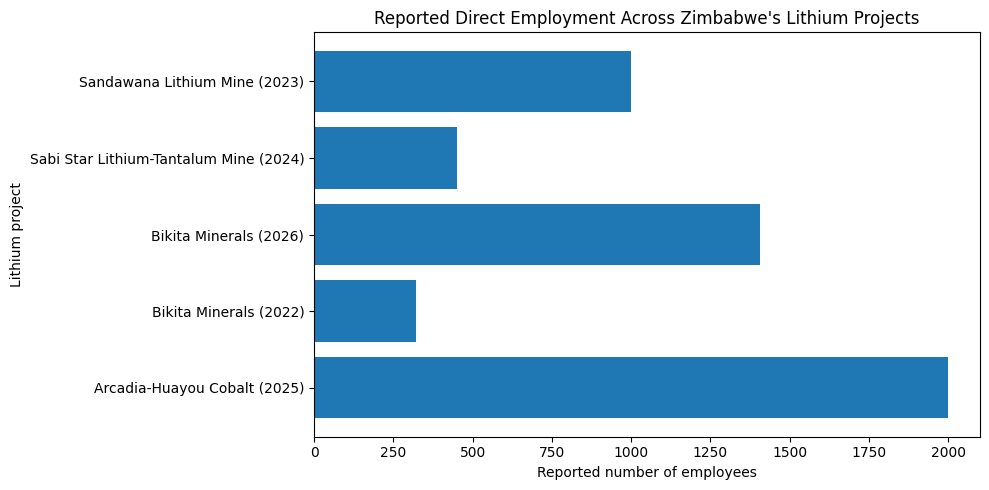

In [13]:

import matplotlib.pyplot as plt

# Select employment observations
employment = core_data[
    core_data["Indicator"].str.contains(
        "Employment", case=False, na=False
    )
].copy()

# Attach project names
project_names = projects.set_index(
    "Project_ID"
)["Project_Name"]

employment["Project"] = employment["Project_ID"].map(
    project_names
)

# Create labels including observation year
employment["Label"] = (
    employment["Project"] + " (" +
    employment["Year"].astype(str) + ")"
)

# Display the data before plotting
display(
    employment[
        ["Project", "Year", "Indicator", "Value", "Unit"]
    ]
)

# Create chart
plt.figure(figsize=(10, 5))

plt.barh(
    employment["Label"],
    employment["Value"]
)

plt.xlabel("Reported number of employees")
plt.ylabel("Lithium project")
plt.title("Reported Direct Employment Across Zimbabwe's Lithium Projects")

plt.tight_layout()
plt.show()


### Research Question 1 & 2 Data Extraction: Investment, Employment, Production & Beneficiation
We will restructure the observations into a readable comparative table focusing on key indicators.

In [ ]:
import pandas as pd

# Let's pivot and display key metrics for each core project to address RQ1 & RQ2
pivot_df = core_data.pivot_table(
    index=['Project_ID', 'Indicator'],
    values=['Year', 'Value', 'Unit'],
    aggfunc='first'
).reset_index()

pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.1f' % x if x > 1e3 else '%.3f' % x)

print("--- DETAILED INDICATORS PER CORE PROJECT ---")
display(pivot_df.sort_values(by=['Project_ID', 'Indicator']))

### Research Question 3 Data Extraction: Ownership & Control
We will pull the project name, location, and registry details related to ownership.

In [15]:
# Show project registry columns to identify ownership information
print("--- PROJECT REGISTRY DETAIL ---")
registry_cols = [col for col in projects.columns if any(x in col.lower() for x in ['owner', 'parent', 'id', 'name', 'country', 'share', 'equity'])]
display(core_projects[registry_cols if len(registry_cols) > 0 else core_projects.columns].head())

--- PROJECT REGISTRY DETAIL ---


,Project_ID,Project_Name,First_Evidence_Year,Source_IDs
0,Zim_L1,Arcadia-Huayou Cobalt,2016,SRC_01; SRC_08; SRC_09; SRC_17; SRC_25; SRC_32
1,Zim_L2,Bikita Minerals,1950,SRC_01; SRC_02; SRC_10; SRC_16; SRC_18; SRC_24...
2,Zim_L3,Sabi Star Lithium-Tantalum Mine,2018,SRC_01; SRC_02; SRC_11; SRC_16; SRC_19; SRC_27
3,Zim_L4,Sandawana Lithium Mine,2022,SRC_01; SRC_02; SRC_12; SRC_20; SRC_24


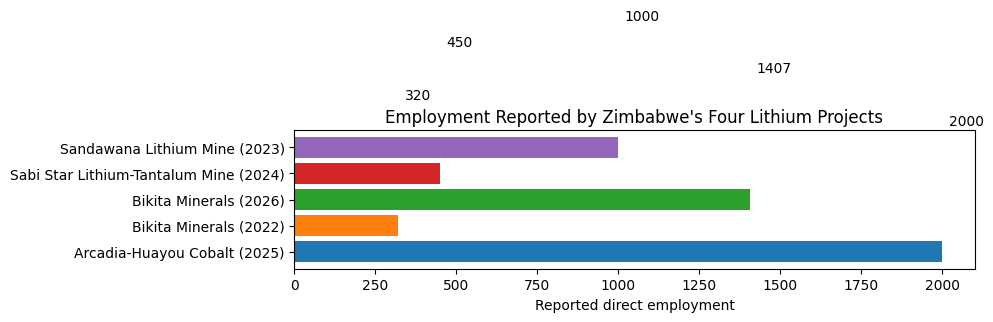

In [16]:

plt.figure(figsize=(10, 6))

for _, row in employment.iterrows():
    plt.barh(
        f"{row['Project']} ({int(row['Year'])})",
        row["Value"]
    )

    plt.text(
        row["Value"] + 20,
        f"{row['Value']:.0f}",
        f"{row['Value']:.0f}",
        va="center"
    )

plt.xlabel("Reported direct employment")
plt.title("Employment Reported by Zimbabwe's Four Lithium Projects")

plt.tight_layout()
plt.show()


In [19]:
import pandas as pd

# Filter for investment-related indicators
investment_indicators = [
    'Acquisition_Price_Paid',
    'Capex_Spent_Reported',
    'Capex_Spent_Sulphate_Plant',
    'Capex_Spent_Expansion',
    'Capex_Committed',
    'Capex_Planned_Announced'
]

investment_data = core_data[core_data['Indicator'].isin(investment_indicators)].copy()

# Map project names
project_names = core_projects.set_index('Project_ID')['Project_Name']
investment_data['Project_Name'] = investment_data['Project_ID'].map(project_names)

# Define categorisation mapping
def categorize_investment(indicator):
    if 'Acquisition' in indicator:
        return 'Acquisition Price Paid'
    elif 'Spent' in indicator:
        return 'Capex Spent (Actual)'
    elif 'Committed' in indicator:
        return 'Capex Committed'
    elif 'Planned' in indicator or 'Announced' in indicator:
        return 'Capex Planned / Announced'
    return 'Other'

investment_data['Category'] = investment_data['Indicator'].apply(categorize_investment)

# Create a structured comparative view
investment_pivot = investment_data.pivot_table(
    index=['Project_Name', 'Project_ID'],
    columns='Category',
    values='Value',
    aggfunc='sum'
).fillna(0)

# Format for monetary readability (Millions USD)
investment_pivot_m = investment_pivot / 1_000_000

print("--- INVESTMENT METRICS BY CATEGORY (in USD Millions) ---")
display(investment_pivot_m.style.format("${:,.1f}M"))

--- INVESTMENT METRICS BY CATEGORY (in USD Millions) ---


,Category,Acquisition Price Paid,Capex Committed,Capex Planned / Announced,Capex Spent (Actual)
Project_Name,Project_ID,,,,
Arcadia-Huayou Cobalt,Zim_L1,$422.0M,$0.0M,$0.0M,$700.0M
Bikita Minerals,Zim_L2,$180.0M,$400.0M,$0.0M,$300.0M
Sabi Star Lithium-Tantalum Mine,Zim_L3,$76.5M,$0.0M,$244.0M,$0.0M
Sandawana Lithium Mine,Zim_L4,$0.0M,$250.0M,$0.0M,$0.0M


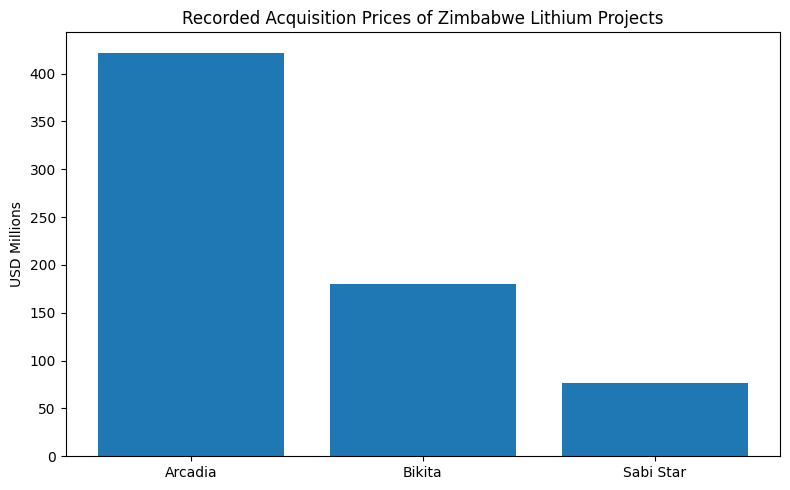

In [20]:

import matplotlib.pyplot as plt

acquisition = {
    "Arcadia": 422,
    "Bikita": 180,
    "Sabi Star": 76.5
}

plt.figure(figsize=(8, 5))
plt.bar(acquisition.keys(), acquisition.values())

plt.ylabel("USD Millions")
plt.title("Recorded Acquisition Prices of Zimbabwe Lithium Projects")

plt.tight_layout()
plt.show()


Capital expenditure comparison

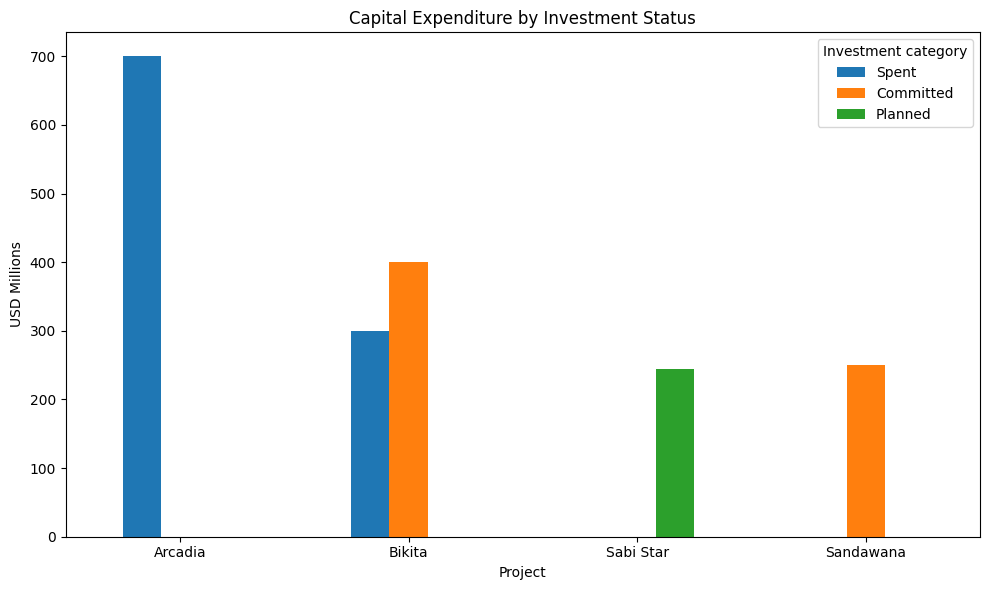

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

capex_data = {
    "Project": ["Arcadia", "Bikita", "Sabi Star", "Sandawana"],
    "Spent": [700, 300, None, None],
    "Committed": [None, 400, None, 250],
    "Planned": [None, None, 244, None]
}

capex_df = pd.DataFrame(capex_data)

capex_df.set_index("Project").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("USD Millions")
plt.title("Capital Expenditure by Investment Status")
plt.xticks(rotation=0)
plt.legend(title="Investment category")
plt.tight_layout()
plt.show()


STEP 5

In [24]:

findings = pd.DataFrame({
    "Finding": [
        "Foreign ownership and acquisition",
        "Investment status",
        "Employment generation",
        "Beneficiation and processing"
    ],
    "Research_Question": [
        "Who owns and controls the lithium projects?",
        "How much investment is spent, committed or planned?",
        "What employment opportunities are generated?",
        "How much processing and value addition takes place locally?"
    ],
    "Interpretation": [
        "Examine foreign ownership and control over lithium assets.",
        "Distinguish actual capital expenditure from commitments and announcements.",
        "Investigate the quality and distribution of employment benefits.",
        "Examine Zimbabwe's position in the lithium global value chain."
    ],
    "Evidence_Status": [
        "Preliminary",
        "Preliminary",
        "Preliminary",
        "Preliminary"
    ]
})

findings.to_excel(
    "Zimbabwe_Lithium_Preliminary_Findings.xlsx",
    index=False
)

print("Research findings report created successfully!")
display(findings)


Research findings report created successfully!


,Finding,Research_Question,Interpretation,Evidence_Status
0,Foreign ownership and acquisition,Who owns and controls the lithium projects?,Examine foreign ownership and control over lit...,Preliminary
1,Investment status,"How much investment is spent, committed or pla...",Distinguish actual capital expenditure from co...,Preliminary
2,Employment generation,What employment opportunities are generated?,Investigate the quality and distribution of em...,Preliminary
3,Beneficiation and processing,How much processing and value addition takes p...,Examine Zimbabwe's position in the lithium glo...,Preliminary


In [23]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=findings)

MessageError: Error: credential propagation was unsuccessful

In [27]:
findings.to_csv(
    "Zimbabwe_Lithium_Preliminary_Findings.csv",
    index=False
)